In [4]:
import cupy as cp
import numpy as np
import time
from tensorflow.keras.datasets import mnist

# 1. Download real MNIST dataset (60,000 training + 10,000 test images)
print("Downloading MNIST handwritten digits dataset...")
(X_train_raw, y_train_raw), (X_test_raw, y_test_raw) = mnist.load_data()

# 2. Flatten 28x28 images into 784 pixel vectors and normalize to [0, 1] in FP32
X_train = cp.asarray(X_train_raw.reshape(-1, 784), dtype=cp.float32) / 255.0
X_test = cp.asarray(X_test_raw.reshape(-1, 784), dtype=cp.float32) / 255.0

y_train = cp.asarray(y_train_raw, dtype=cp.int32)
y_test = cp.asarray(y_test_raw, dtype=cp.int32)

# One-hot encode training labels for cross-entropy loss
Y_train_oh = cp.eye(10, dtype=cp.float32)[y_train]

print(f"Training data shape in GPU VRAM : {X_train.shape} (60,000 images, 784 pixels each)")
print(f"Testing data shape in GPU VRAM  : {X_test.shape} (10,000 unseen test images)")

Training data shape in GPU VRAM : (60000, 784) (60,000 images, 784 pixels each)
Testing data shape in GPU VRAM  : (10000, 784) (10,000 unseen test images)


In [5]:
# Mini-Batch Training (Updates weights every 128 images instead of once per 60,000)
cp.random.seed(42)

W1 = cp.random.randn(784, 512, dtype=cp.float32) * cp.sqrt(2.0 / 784, dtype=cp.float32)
b1 = cp.zeros((1, 512), dtype=cp.float32)
W2 = cp.random.randn(512, 256, dtype=cp.float32) * cp.sqrt(2.0 / 512, dtype=cp.float32)
b2 = cp.zeros((1, 256), dtype=cp.float32)
W3 = cp.random.randn(256, 10, dtype=cp.float32) * cp.sqrt(2.0 / 256, dtype=cp.float32)
b3 = cp.zeros((1, 10), dtype=cp.float32)

batch_size = 128
learning_rate = cp.float32(0.1)
epochs = 15  # Only 15 epochs needed because each epoch now does 468 weight updates!
N = X_train.shape[0]

cp.cuda.Stream.null.synchronize()
start_time = time.perf_counter()

for epoch in range(1, epochs + 1):
    # Shuffle training data each epoch
    perm = cp.random.permutation(N)
    X_shuf = X_train[perm]
    Y_shuf = Y_train_oh[perm]
    
    for i in range(0, N, batch_size):
        xb = X_shuf[i:i+batch_size]
        yb = Y_shuf[i:i+batch_size]
        m = xb.shape[0]
        
        # Forward
        z1 = xb @ W1 + b1
        a1 = cp.maximum(0, z1)
        z2 = a1 @ W2 + b2
        a2 = cp.maximum(0, z2)
        z3 = a2 @ W3 + b3
        
        exp_s = cp.exp(z3 - cp.max(z3, axis=1, keepdims=True))
        probs = exp_s / cp.sum(exp_s, axis=1, keepdims=True)
        
        # Backward
        dz3 = (probs - yb) / m
        dW3 = a2.T @ dz3
        db3 = cp.sum(dz3, axis=0, keepdims=True)
        
        da2 = dz3 @ W3.T
        dz2 = da2 * (z2 > 0)
        dW2 = a1.T @ dz2
        db2 = cp.sum(dz2, axis=0, keepdims=True)
        
        da1 = dz2 @ W2.T
        dz1 = da1 * (z1 > 0)
        dW1 = xb.T @ dz1
        db1 = cp.sum(dz1, axis=0, keepdims=True)
        
        # Update
        W3 -= learning_rate * dW3
        b3 -= learning_rate * db3
        W2 -= learning_rate * dW2
        b2 -= learning_rate * db2
        W1 -= learning_rate * dW1
        b1 -= learning_rate * db1

    # Evaluate on unseen test set
    t_a1 = cp.maximum(0, X_test @ W1 + b1)
    t_a2 = cp.maximum(0, t_a1 @ W2 + b2)
    t_z3 = t_a2 @ W3 + b3
    acc = float(cp.mean(cp.argmax(t_z3, axis=1) == y_test)) * 100
    print(f"Epoch {epoch:2d}/{epochs} | Unseen Test Accuracy: {acc:.2f}%")

cp.cuda.Stream.null.synchronize()
print(f"\nDone in {time.perf_counter() - start_time:.2f}s! Now re-run your plotting cell.")

Epoch  1/15 | Unseen Test Accuracy: 94.25%
Epoch  2/15 | Unseen Test Accuracy: 95.74%
Epoch  3/15 | Unseen Test Accuracy: 96.56%
Epoch  4/15 | Unseen Test Accuracy: 96.63%
Epoch  5/15 | Unseen Test Accuracy: 97.41%
Epoch  6/15 | Unseen Test Accuracy: 97.55%
Epoch  7/15 | Unseen Test Accuracy: 97.60%
Epoch  8/15 | Unseen Test Accuracy: 97.49%
Epoch  9/15 | Unseen Test Accuracy: 97.84%
Epoch 10/15 | Unseen Test Accuracy: 97.87%
Epoch 11/15 | Unseen Test Accuracy: 97.91%
Epoch 12/15 | Unseen Test Accuracy: 97.82%
Epoch 13/15 | Unseen Test Accuracy: 97.99%
Epoch 14/15 | Unseen Test Accuracy: 97.94%
Epoch 15/15 | Unseen Test Accuracy: 98.01%

Done in 9.58s! Now re-run your plotting cell.


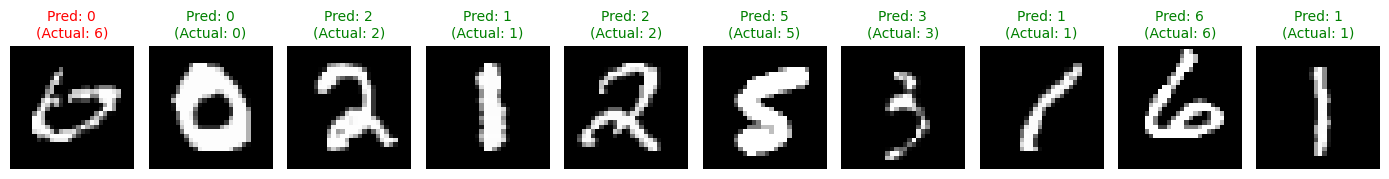

In [6]:
import matplotlib.pyplot as plt

# Pick 10 random images from the unseen test set
indices = np.random.choice(len(X_test_raw), size=10, replace=False)
sample_images = X_test[indices]

# Run forward pass on those 10 images to get the AI's predictions
h1 = cp.maximum(0, sample_images @ W1 + b1)
h2 = cp.maximum(0, h1 @ W2 + b2)
out = h2 @ W3 + b3
preds = cp.asnumpy(cp.argmax(out, axis=1))

# Plot the images and predictions
plt.figure(figsize=(14, 3))
for i, idx in enumerate(indices):
    plt.subplot(1, 10, i + 1)
    plt.imshow(X_test_raw[idx], cmap="gray")
    actual = y_test_raw[idx]
    pred = preds[i]
    color = "green" if pred == actual else "red"
    plt.title(f"Pred: {pred}\n(Actual: {actual})", color=color, fontsize=10)
    plt.axis("off")
plt.tight_layout()
plt.show()